# Практика: Влияние инициализации и скорости обучения на MNIST

В этом практическом занятии мы исследуем, как начальная инициализация весов и скорость обучения влияют на обучение нейронной сети на реальном наборе данных MNIST (рукописные цифры). Мы будем использовать простую полносвязную сеть (MLP) с двумя скрытыми слоями.

**Цели:**
- Научиться загружать и подготавливать данные MNIST.
- Сравнить различные инициализации (по умолчанию, Xavier, He, случайная большая).
- Исследовать влияние скорости обучения на сходимость.
- Визуализировать процесс обучения и полученные признаки.

**Задание: повторить все действия и сделать выводы для набора данных Fashion-MNIST.**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

# Фиксируем seed для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 1. Загрузка и предобработка данных MNIST

Загрузим обучающую и тестовую выборки, нормализуем изображения и создадим DataLoader'ы. Для ускорения эксперимента возьмём только первые 10000 обучающих примеров и 2000 тестовых.

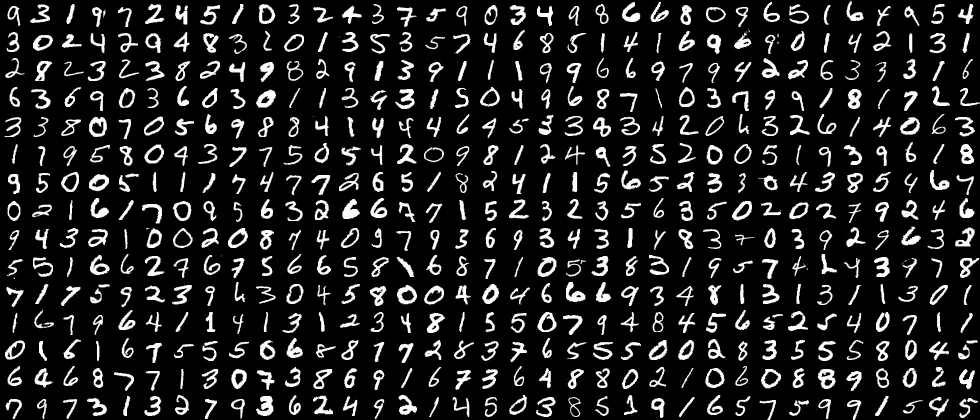

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # среднее и std для MNIST
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Ограничим выборку для быстроты
train_dataset = torch.utils.data.Subset(train_dataset, range(10000))
test_dataset = torch.utils.data.Subset(test_dataset, range(2000))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 490kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.51MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.10MB/s]


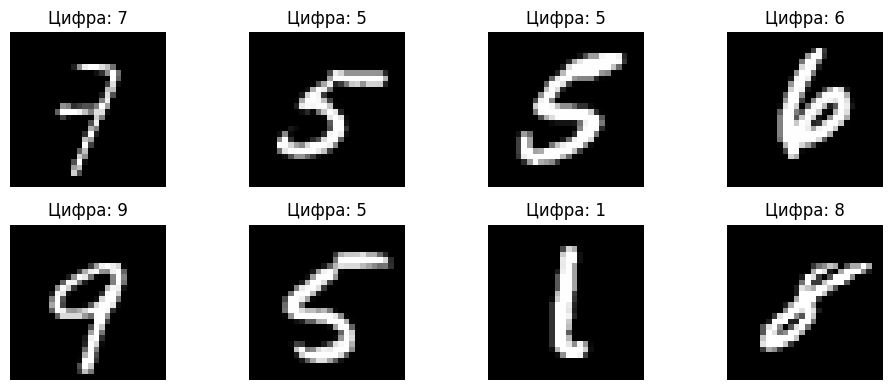

In [ ]:
# Посмотрим на несколько изображений
images, labels = next(iter(train_loader))
plt.figure(figsize=(10,4))
for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i][0], cmap='gray')
    plt.title(f'Цифра: {labels[i].item()}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Определение модели

Создадим MLP с двумя скрытыми слоями (256 и 128 нейронов) и выходным слоем на 10 классов (softmax не включаем, так как будем использовать CrossEntropyLoss).

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden1=256, hidden2=128, output_size=10):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden2, output_size)
        # без softmax, его добавит loss

    def forward(self, x):
        x = x.view(x.size(0), -1)  # вытягиваем изображения в вектор
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

# инициализация весов перед обучением
def init_weights(m, mode='default'):
    if isinstance(m, nn.Linear):
        if mode == 'normal':
            nn.init.normal_(m.weight, mean=0, std=1.0)
            nn.init.zeros_(m.bias)
        elif mode == 'xavier':
            nn.init.xavier_normal_(m.weight)
            nn.init.zeros_(m.bias)
        elif mode == 'he':
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            nn.init.zeros_(m.bias)
        elif mode == 'default':
            pass  # оставляем умолчательную

## 3. Функция для обучения и оценки

Определим функцию, которая принимает модель, загрузчики, число эпох, скорость обучения и тип инициализации, обучает и возвращает историю потерь и точности.

In [ ]:
def train_and_evaluate(model, train_loader, test_loader, epochs=5, lr=0.01, init_mode='default'):
    model.apply(lambda m: init_weights(m, init_mode)) # инициализация весов на всех слоях модели
    criterion = nn.CrossEntropyLoss() # создание функции потерь - кросс-энтропии
    optimizer = optim.SGD(model.parameters(), lr=lr) # создание оптимизатора

    # Пустые массивы для накопления истории обучения
    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []

    for epoch in range(epochs):
        # перевод модели в режим обучения
        model.train()

        # инициализация счетчиков для накопления статистики за текущую эпоху
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # перебор всех данных из обучающей выборки
        for images, labels in train_loader:
            # обнуление градиентов
            optimizer.zero_grad()
            # прямой проход, прогоняем батч через модель, получаем выходные значения (до softmax) размером (batch_size, 10)
            outputs = model(images)
            # текущее значение функции потерь для батча
            loss = criterion(outputs, labels)
            # вычисление градиентов
            loss.backward()

            # обновление весов модели на основе градиентов
            optimizer.step()

            # среднюю ошибку умножаем на все примеры в батче (* images.size(0))
            running_loss += loss.item() * images.size(0)

            # индекс максимального значения по строке
            _, predicted = torch.max(outputs, 1)

            # увеличиваем счетчик общего количества примеров и количество правильно предсказанных
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        # Обновление метрик после прохода всех данных
        epoch_train_loss = running_loss / len(train_loader.dataset) # ошибка на эпохе
        epoch_train_acc = correct_train / total_train # точность на эпохе
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc)

        # Оценка на тесте
        # перевод модели в режим оценки
        model.eval()
        test_loss = 0.0
        correct_test = 0
        total_test = 0
        with torch.no_grad(): # отключение вычислений градиентов
            for images, labels in test_loader:
                outputs = model(images)
                loss = criterion(outputs, labels)
                test_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()

        epoch_test_loss = test_loss / len(test_loader.dataset)
        epoch_test_acc = correct_test / total_test
        test_losses.append(epoch_test_loss)
        test_accs.append(epoch_test_acc)

        print(f'Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.4f}')

    return train_losses, test_losses, train_accs, test_accs

## 4. Эксперимент 1: Сравнение инициализаций

Зафиксируем скорость обучения `lr = 0.01` и сравним четыре инициализации: по умолчанию, Xavier, He, случайная нормальная с большой дисперсией (std=1). Обучим каждую модель в течение 5 эпох.

In [ ]:
init_modes = ['default', 'xavier', 'he', 'normal']
histories = {}

for mode in init_modes:
    print(f"\n=== Инициализация: {mode} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader, test_loader, epochs=5, lr=0.01, init_mode=mode
    )
    histories[mode] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Инициализация: default ===
Epoch 1/5 | Train Loss: 1.9573 | Test Loss: 1.5251 | Test Acc: 0.6850
Epoch 2/5 | Train Loss: 0.9627 | Test Loss: 0.8017 | Test Acc: 0.7930
Epoch 3/5 | Train Loss: 0.5600 | Test Loss: 0.5963 | Test Acc: 0.8350
Epoch 4/5 | Train Loss: 0.4358 | Test Loss: 0.5180 | Test Acc: 0.8490
Epoch 5/5 | Train Loss: 0.3774 | Test Loss: 0.4679 | Test Acc: 0.8630

=== Инициализация: xavier ===
Epoch 1/5 | Train Loss: 0.9504 | Test Loss: 0.6451 | Test Acc: 0.8095
Epoch 2/5 | Train Loss: 0.4182 | Test Loss: 0.4899 | Test Acc: 0.8550
Epoch 3/5 | Train Loss: 0.3267 | Test Loss: 0.4220 | Test Acc: 0.8755
Epoch 4/5 | Train Loss: 0.2783 | Test Loss: 0.3885 | Test Acc: 0.8895
Epoch 5/5 | Train Loss: 0.2462 | Test Loss: 0.3631 | Test Acc: 0.8935

=== Инициализация: he ===
Epoch 1/5 | Train Loss: 0.8637 | Test Loss: 0.5982 | Test Acc: 0.8280
Epoch 2/5 | Train Loss: 0.3863 | Test Loss: 0.4546 | Test Acc: 0.8650
Epoch 3/5 | Train Loss: 0.3005 | Test Loss: 0.3974 | Test Acc: 0.8850


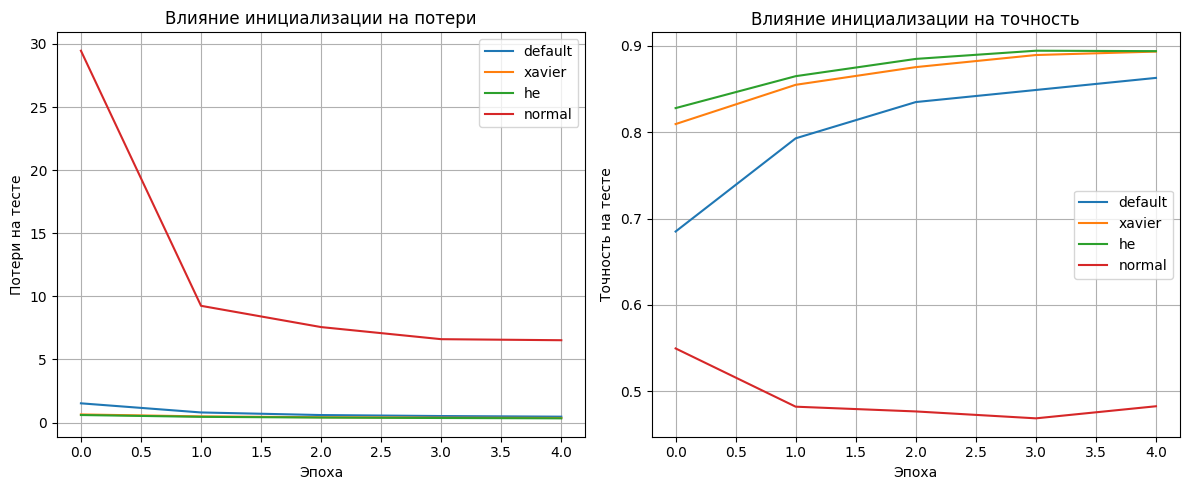

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for mode in init_modes:
    plt.plot(histories[mode]['test_loss'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние инициализации на потери')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for mode in init_modes:
    plt.plot(histories[mode]['test_acc'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние инициализации на точность')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Вопросы для анализа:**
- Какая инициализация обеспечила наилучшую точность?
- Почему инициализация 'normal' (std=1) работает хуже?
- Соответствуют ли результаты теоретическим ожиданиям (He лучше для ReLU)?

Ответ:
1) Наилучшую точность показала инициализация "he".
2) Инициализация "normal" сработала хуже, т.к. начальные веса оказались слишком большими, из-за чего потери стали большими.
3) Да, результаты соответствуют ожидаениям. "he" показала наилучшую точность и наименьшие потери, а также стабильное обучения, без скачков и переобучения.

## 5. Эксперимент 2: Влияние скорости обучения

Теперь зафиксируем инициализацию He (как лучшую для ReLU) и сравним три значения скорости обучения: 0.001, 0.01, 0.1.

In [ ]:
lrs = [0.001, 0.01, 0.1, 1.0]
lr_histories = {}

for lr in lrs:
    print(f"\n=== Learning rate: {lr} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader, test_loader, epochs=5, lr=lr, init_mode='he'
    )
    lr_histories[lr] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Learning rate: 0.001 ===
Epoch 1/5 | Train Loss: 2.1187 | Test Loss: 1.7180 | Test Acc: 0.4480
Epoch 2/5 | Train Loss: 1.3072 | Test Loss: 1.2668 | Test Acc: 0.6265
Epoch 3/5 | Train Loss: 0.9654 | Test Loss: 1.0302 | Test Acc: 0.7055
Epoch 4/5 | Train Loss: 0.7852 | Test Loss: 0.8881 | Test Acc: 0.7425
Epoch 5/5 | Train Loss: 0.6765 | Test Loss: 0.7957 | Test Acc: 0.7690

=== Learning rate: 0.01 ===
Epoch 1/5 | Train Loss: 0.8986 | Test Loss: 0.6154 | Test Acc: 0.8110
Epoch 2/5 | Train Loss: 0.4015 | Test Loss: 0.4750 | Test Acc: 0.8660
Epoch 3/5 | Train Loss: 0.3140 | Test Loss: 0.4158 | Test Acc: 0.8760
Epoch 4/5 | Train Loss: 0.2674 | Test Loss: 0.3767 | Test Acc: 0.8875
Epoch 5/5 | Train Loss: 0.2342 | Test Loss: 0.3553 | Test Acc: 0.8975

=== Learning rate: 0.1 ===
Epoch 1/5 | Train Loss: 0.4489 | Test Loss: 0.4290 | Test Acc: 0.8535
Epoch 2/5 | Train Loss: 0.1702 | Test Loss: 0.5143 | Test Acc: 0.8345
Epoch 3/5 | Train Loss: 0.1082 | Test Loss: 0.2904 | Test Acc: 0.9050
Epo

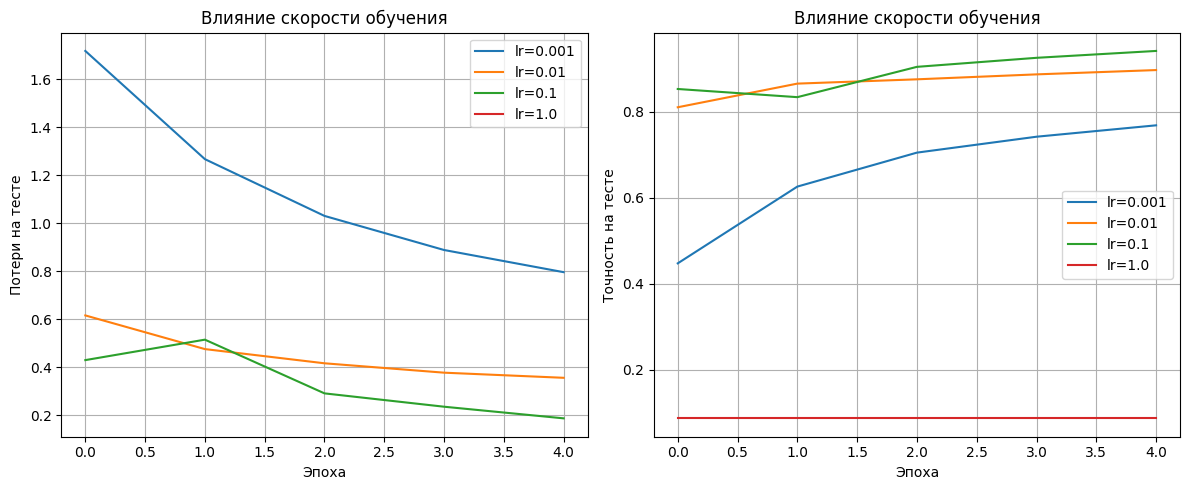

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_loss'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_acc'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Вопросы:**
- Какое значение learning rate дало наилучший результат?
- Наблюдается ли переобучение или недообучение при каком-либо lr?
- Что произойдёт, если взять lr = 1.0? (можно проверить самостоятельно)

Ответ:
1) Наилучшый результат показала lr=0.01
2) Переобучение наблюдается у lr=0.1 (после 3 эпохи сильно упала точность на тесте). Недообучение на первый взгляд не встречено (у lr=0.001 видны заметные потери и небольшая точность на протяжении 5 эпох, возможно показатели улучшатся с еще большим кол-ом эпох)
3) Для lr=1.0 слишком большие потери и слишком маленькая точность, это связано с большими шагами при изменении весов во время обучения.

## 6. Визуализация весов первого слоя

Для лучшей модели (например, He + lr=0.01) визуализируем веса первого слоя как изображения 28x28, чтобы увидеть, какие паттерны выучили нейроны.

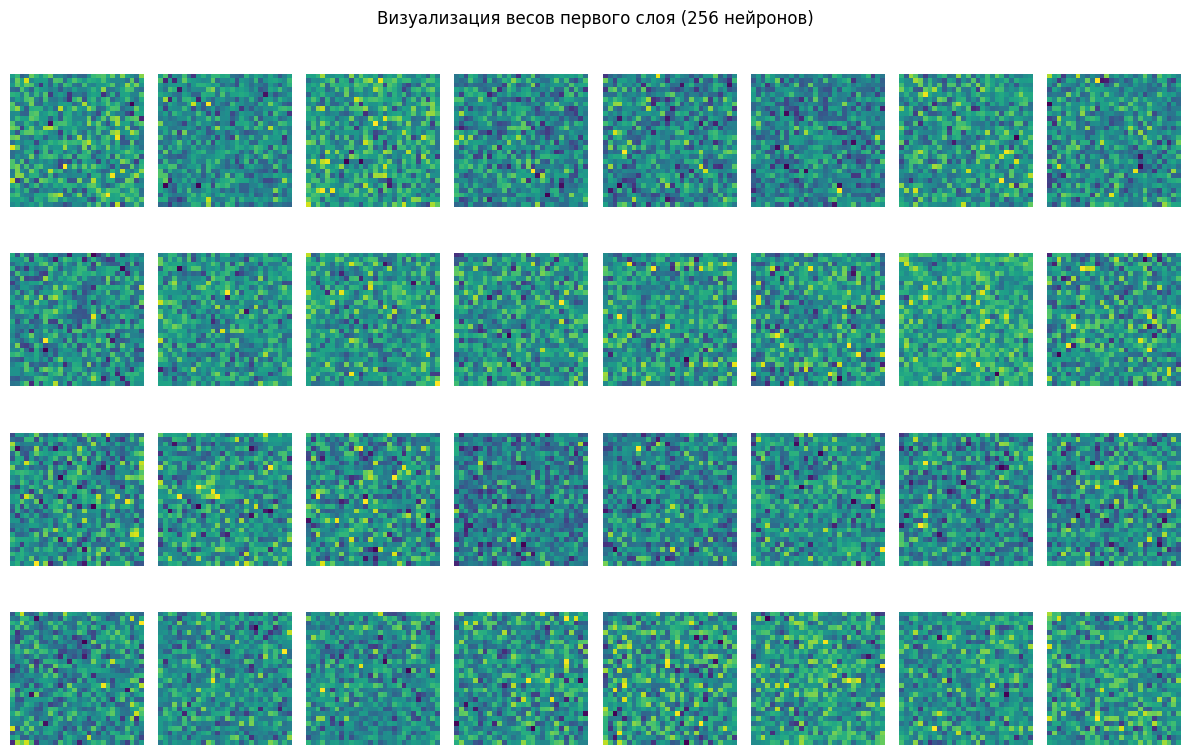

In [ ]:
best_model = histories['he']['model']  # из первого эксперимента
weights = best_model.fc1.weight.detach().cpu().numpy()  # (256, 784)

# Отобразим первые 32 нейрона
plt.figure(figsize=(12,8))
for i in range(32):
    plt.subplot(4,8,i+1)
    w = weights[i].reshape(28,28)
    plt.imshow(w, cmap='viridis')
    plt.axis('off')
plt.suptitle('Визуализация весов первого слоя (256 нейронов)')
plt.tight_layout()
plt.show()

## 7. Выводы

В этом практическом занятии мы:
- Загрузили реальный набор данных MNIST и построили простой MLP.
- Сравнили различные инициализации весов и убедились, что Xavier и He дают лучшую сходимость, чем случайная большая инициализация.
- Исследовали влияние скорости обучения и увидели, что слишком маленький шаг замедляет обучение, а слишком большой может привести к нестабильности.
- Визуализировали веса первого слоя, которые показывают, что нейроны учатся распознавать характерные штрихи цифр.

Эти эксперименты демонстрируют важность правильного выбора гиперпараметров при обучении нейросетей.

# Работа с датасетом Fashion-MNIST




In [ ]:
transform_f = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))  # среднее и std для MNIST
])

train_dataset_f = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform_f)
test_dataset_f = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform_f)

# Ограничим выборку для быстроты
train_dataset_f = torch.utils.data.Subset(train_dataset_f, range(10000))
test_dataset_f = torch.utils.data.Subset(test_dataset_f, range(2000))

train_loader_f = DataLoader(train_dataset_f, batch_size=64, shuffle=True)
test_loader_f = DataLoader(test_dataset_f, batch_size=64, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.34MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.7MB/s]


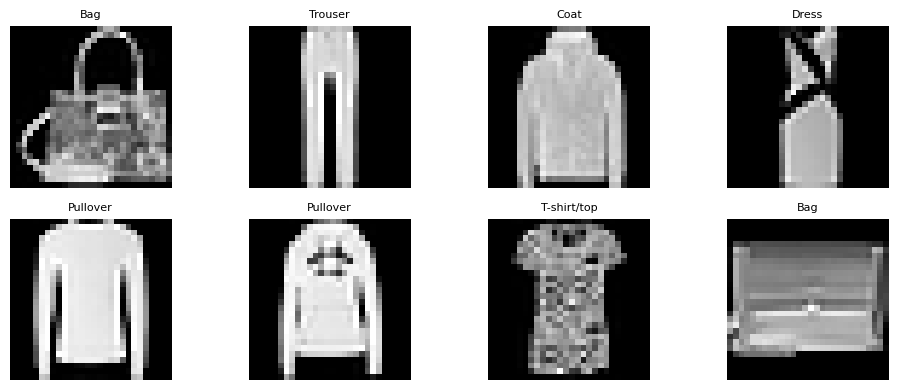

In [ ]:
# Посмотрим на несколько изображений
fashion_classes = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

images, labels = next(iter(train_loader_f))
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i][0], cmap='gray')
    plt.title(fashion_classes[labels[i].item()], fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
init_modes = ['default', 'xavier', 'he', 'normal']
histories = {}

for mode in init_modes:
    print(f"\n=== Инициализация: {mode} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader_f, test_loader_f, epochs=5, lr=0.01, init_mode=mode
    )
    histories[mode] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Инициализация: default ===
Epoch 1/5 | Train Loss: 1.7468 | Test Loss: 1.1879 | Test Acc: 0.6250
Epoch 2/5 | Train Loss: 0.9397 | Test Loss: 0.8109 | Test Acc: 0.7155
Epoch 3/5 | Train Loss: 0.7245 | Test Loss: 0.6798 | Test Acc: 0.7625
Epoch 4/5 | Train Loss: 0.6354 | Test Loss: 0.6319 | Test Acc: 0.7755
Epoch 5/5 | Train Loss: 0.5874 | Test Loss: 0.5866 | Test Acc: 0.7900

=== Инициализация: xavier ===
Epoch 1/5 | Train Loss: 0.9615 | Test Loss: 0.6929 | Test Acc: 0.7445
Epoch 2/5 | Train Loss: 0.5965 | Test Loss: 0.5638 | Test Acc: 0.8045
Epoch 3/5 | Train Loss: 0.5214 | Test Loss: 0.5685 | Test Acc: 0.7870
Epoch 4/5 | Train Loss: 0.4804 | Test Loss: 0.5227 | Test Acc: 0.8095
Epoch 5/5 | Train Loss: 0.4525 | Test Loss: 0.5226 | Test Acc: 0.8115

=== Инициализация: he ===
Epoch 1/5 | Train Loss: 0.9334 | Test Loss: 0.7189 | Test Acc: 0.7610
Epoch 2/5 | Train Loss: 0.5806 | Test Loss: 0.5618 | Test Acc: 0.8020
Epoch 3/5 | Train Loss: 0.5073 | Test Loss: 0.5616 | Test Acc: 0.7950


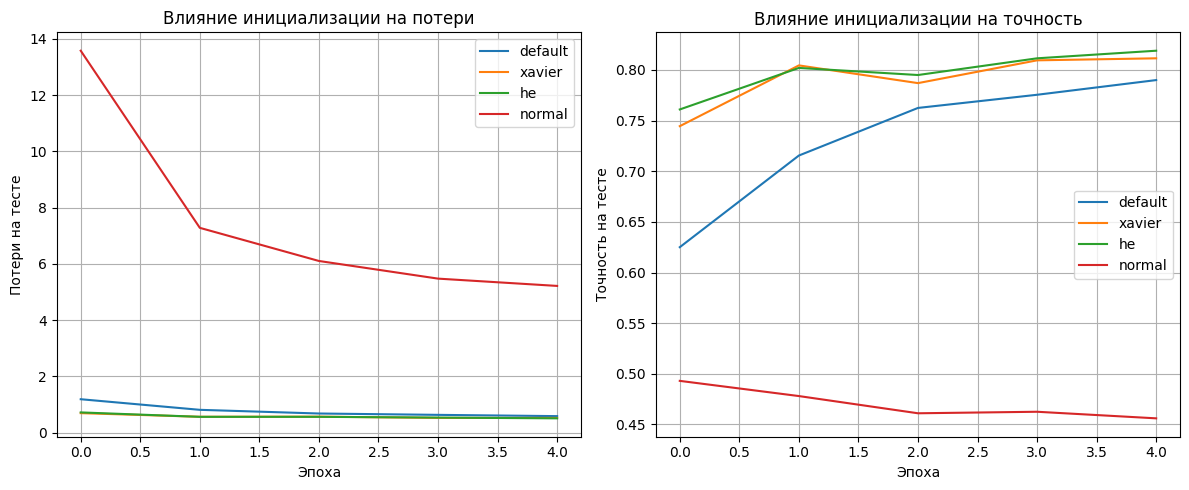

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for mode in init_modes:
    plt.plot(histories[mode]['test_loss'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние инициализации на потери')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for mode in init_modes:
    plt.plot(histories[mode]['test_acc'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние инициализации на точность')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

На датасете Fashion-MNIST лучшую точность показала инициализация "he", худшую - "normal" (как и в MNIST). "normal" точно так же имеет большие потери из-за больших начальных весов.

In [ ]:
lrs = [0.001, 0.01, 0.1, 1.0]
lr_histories = {}

for lr in lrs:
    print(f"\n=== Learning rate: {lr} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader_f, test_loader_f, epochs=5, lr=lr, init_mode='he'
    )
    lr_histories[lr] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Learning rate: 0.001 ===
Epoch 1/5 | Train Loss: 1.7266 | Test Loss: 1.2554 | Test Acc: 0.5735
Epoch 2/5 | Train Loss: 1.0873 | Test Loss: 1.0152 | Test Acc: 0.6505
Epoch 3/5 | Train Loss: 0.9248 | Test Loss: 0.9039 | Test Acc: 0.6825
Epoch 4/5 | Train Loss: 0.8371 | Test Loss: 0.8362 | Test Acc: 0.7075
Epoch 5/5 | Train Loss: 0.7793 | Test Loss: 0.7843 | Test Acc: 0.7255

=== Learning rate: 0.01 ===
Epoch 1/5 | Train Loss: 0.9034 | Test Loss: 0.6656 | Test Acc: 0.7635
Epoch 2/5 | Train Loss: 0.5783 | Test Loss: 0.5769 | Test Acc: 0.7870
Epoch 3/5 | Train Loss: 0.5050 | Test Loss: 0.5299 | Test Acc: 0.8075
Epoch 4/5 | Train Loss: 0.4650 | Test Loss: 0.5014 | Test Acc: 0.8245
Epoch 5/5 | Train Loss: 0.4335 | Test Loss: 0.5196 | Test Acc: 0.8120

=== Learning rate: 0.1 ===
Epoch 1/5 | Train Loss: 0.6916 | Test Loss: 0.5883 | Test Acc: 0.7935
Epoch 2/5 | Train Loss: 0.4482 | Test Loss: 0.6918 | Test Acc: 0.7510
Epoch 3/5 | Train Loss: 0.3806 | Test Loss: 0.8901 | Test Acc: 0.7025
Epo

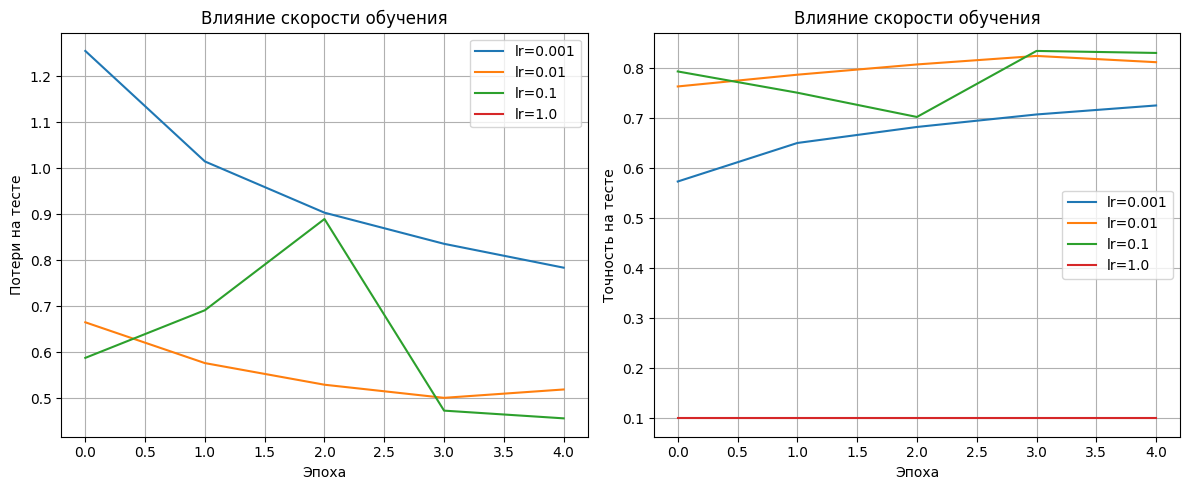

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_loss'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_acc'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

На датасете Fashion-MNIST лучшие точности показали lr=0.01 и lr=0.1

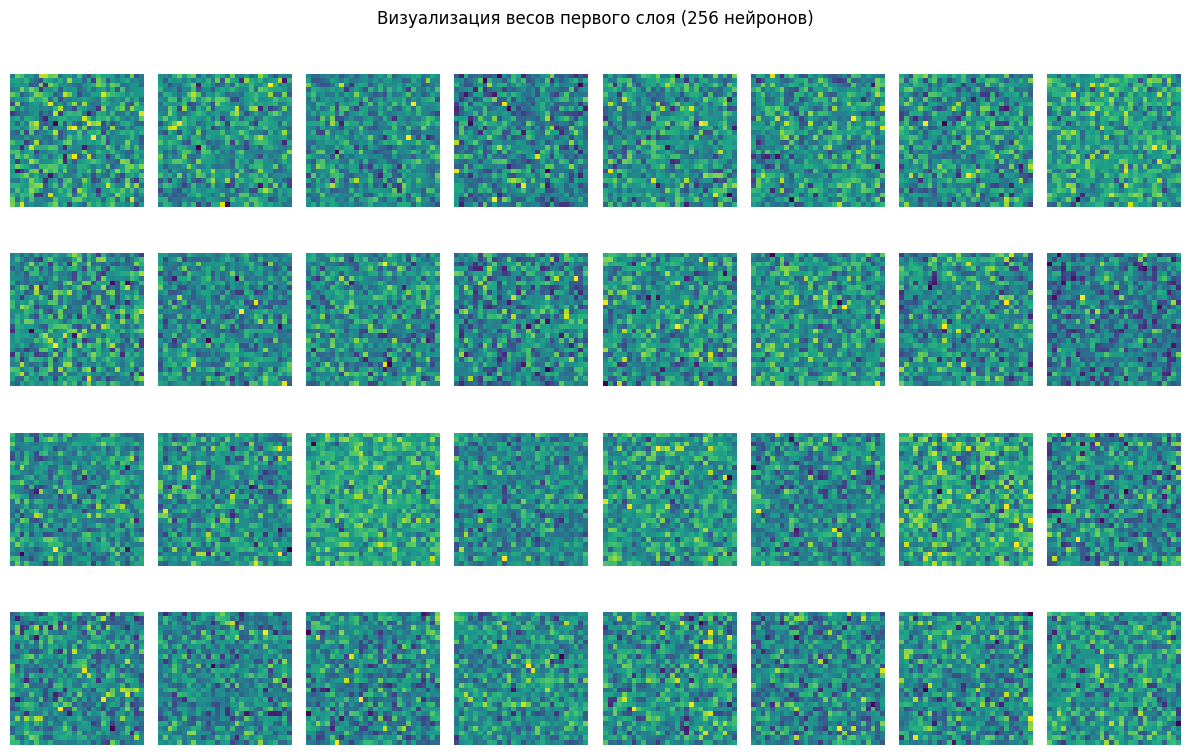

In [ ]:
best_model = histories['he']['model']  # из первого эксперимента
weights = best_model.fc1.weight.detach().cpu().numpy()  # (256, 784)

# Отобразим первые 32 нейрона
plt.figure(figsize=(12,8))
for i in range(32):
    plt.subplot(4,8,i+1)
    w = weights[i].reshape(28,28)
    plt.imshow(w, cmap='viridis')
    plt.axis('off')
plt.suptitle('Визуализация весов первого слоя (256 нейронов)')
plt.tight_layout()
plt.show()